<font size="5">Example to invoke the surrogate and plot light curves of GW170817/AT2017gfo</font>

<font color="red">Please make sure that PyTorch has been installed.</font>

Note: PyTorch in CPU version was used in this work. It's quick enough and the GPU version is not necessary.

Figure is saved: user_guide_lightcurves.png


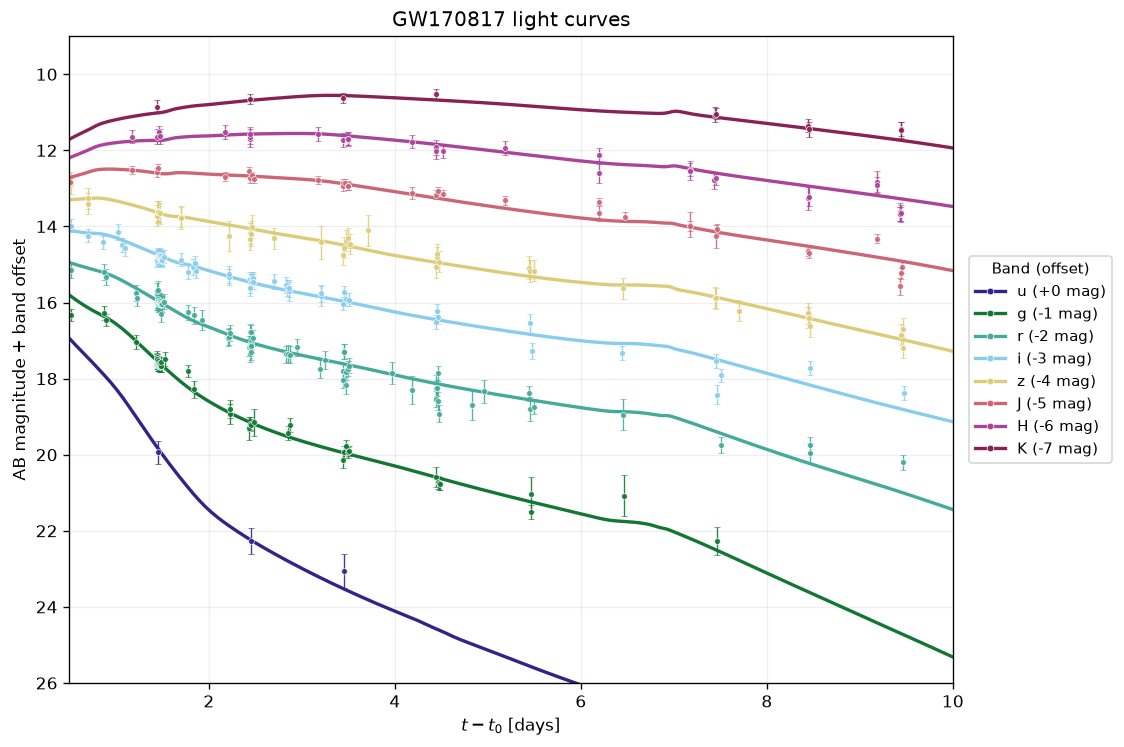

In [5]:
# -*- coding: utf-8 -*-

# %% 1. Parameters
Md = 0.01644542144      # [M_sun], mass of dynamic ejecta
Mn = 0.01960997564      # [M_sun], mass of neutron driven wind
Mv = 0.01668483988      # [M_sun], mass of viscosity driven outflow
vd = 0.2210311698       # [c], RMS velocity of dynamic ejecta
vn = 0.06579671016      # [c], RMS velocity of neutron driven wind
tbreak = 6.691869947        # [day], 
theta = 18.3555284      # [deg],

MODEL_PARAMETERS = [Md, Mn, Mv, vd, vn, tbreak, theta]

# Input files and output files
MODEL_FILE = "BNS_model.pth"  # Do not change
DATA_DIR = "170817"  # Data of GW170817/AT2017gfo
OUTPUT_FIG = "user_guide_lightcurves.png"  # File name of output figure

T0_MJD = 57982.529  # Star time of the event in MJD (GW170817/AT2017gfo)
DISTANCE_PC = 39.5e6  # Luminosity distance in pc

# Effective time range of the model
TIME_MIN = 0.5
TIME_MAX = 10.0
TIME_POINTS = 300

BAND_ORDER = ["u", "g", "r", "i", "z", "J", "H", "K"]
#System error refered from Waxman et al. 2018
SYSTEMATIC_ERRORS = {
    "u": 0.30,
    "g": 0.14,
    "r": 0.20,
    "i": 0.17,
    "z": 0.27,
    "J": 0.10,
    "H": 0.17,
    "K": 0.08,
}
BAND_OFFSETS = {
    "u": 0,
    "g": -1,
    "r": -2,
    "i": -3,
    "z": -4,
    "J": -5,
    "H": -6,
    "K": -7,
}

BAND_COLORS = {
    "u": "#332288",
    "g": "#117733",
    "r": "#44AA99",
    "i": "#88CCEE",
    "z": "#DDCC77",
    "J": "#CC6677",
    "H": "#AA4499",
    "K": "#882255",
}

X_LIMITS = (0.5, 10.0)
Y_LIMITS = (26.0, 9.0)
X_LABEL = r"$t-t_0$ [days]"
Y_LABEL = "AB magnitude + band offset"
TITLE = "GW170817 light curves"
LEGEND_TITLE = "Band (offset)"

FIGSIZE = (9.5, 7.0)
DISPLAY_DPI = 120
SAVE_DPI = 220
SAVE_FIG = True
SHOW_FIG = True
SHOW_GRID = True
SHOW_OBSERVATIONS = True

CURVE_STYLE = {"lw": 2.0}
ERRORBAR_STYLE = {
    "fmt": "o",
    "ms": 3.5,
    "elinewidth": 0.8,
    "capsize": 2,
    "markeredgecolor": "white",
    "markeredgewidth": 0.4,
    "alpha": 0.9,
}
LEGEND_STYLE = {
    "fontsize": 9,
    "title_fontsize": 9,
    "frameon": True,
    "loc": "center left",
    "bbox_to_anchor": (1.01, 0.5),
}
GRID_STYLE = {"alpha": 0.2}

# %% 2. Import packages
import os
from pathlib import Path

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# %% 3. Module of Surrogate
class BNSSurrogate(nn.Module):

    def __init__(self, in_dim=9, width=512, n_hidden=4):
        super().__init__()
        self.inp = nn.Linear(in_dim, width)
        self.hidden = nn.ModuleList(
            [nn.Linear(width, width) for _ in range(n_hidden)]
        )
        self.out = nn.Linear(width, 1)
        self.act = nn.SiLU()

    def forward(self, x):
        h = self.act(self.inp(x))
        for layer in self.hidden:
            h = self.act(h + layer(h))
        return self.out(h)


def load_surrogate_model(model_file):
    model_path = Path(model_file)
    if not model_path.exists():
        raise FileNotFoundError(f"Model file not found: {model_path.resolve()}")

    checkpoint = torch.load(model_path, map_location="cpu", weights_only=False)
    model = BNSSurrogate(**checkpoint["model_config"])
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    normalization = checkpoint["scaler"]
    band_wavelengths = np.asarray(checkpoint["lambdas"], dtype=float)
    return model, normalization, dict(zip(BAND_ORDER, band_wavelengths))


# %% 4. Read data
def load_observations(data_dir):
    observations = {}
    for band in BAND_ORDER:
        file_path = Path(data_dir) / f"M{band}170817.txt"
        if not file_path.exists():
            print(f"Warning: {file_path} is not found，points of {band} band would be ignored")
            continue

        data = np.loadtxt(file_path)
        if data.ndim == 1:
            data = data[None, :]

        time = data[:, 0] - T0_MJD
        selected = (time >= TIME_MIN) & (time <= TIME_MAX)
        statistical_error = data[selected, 2]
        total_error = np.sqrt(
            statistical_error ** 2 + SYSTEMATIC_ERRORS[band] ** 2
        )
        observations[band] = {
            "time": time[selected],
            "magnitude": data[selected, 1],
            "error": total_error,
        }
    return observations

def build_model_features(parameters, times, wavelength, normalization):
    """Normalization. Do not change the values."""
    md, mn, mv, v_d, v_n, t_break, view_angle = parameters
    features = np.column_stack([
        np.full_like(times, np.log10(max(md, 1e-6))),
        np.full_like(times, np.log10(max(mn, 1e-6))),
        np.full_like(times, np.log10(max(mv, 1e-6))),
        np.full_like(times, v_d),
        np.full_like(times, v_n),
        np.full_like(times, np.log10(max(t_break, 1e-3))),
        np.full_like(times, np.cos(np.deg2rad(view_angle))),
        np.log10(times),
        np.full_like(times, np.log10(wavelength)),
    ])
    x_min = normalization["x_min"]
    x_span = normalization["x_span"]
    return (features - x_min) / x_span * 2.0 - 1.0

def predict_ab_magnitudes(parameters, times, wavelength, model, normalization):
    """Predict the AB magnitude."""
    times = np.asarray(times, dtype=float)
    model_input = build_model_features(parameters, times, wavelength,
                                       normalization)
    model_input = torch.tensor(model_input, dtype=torch.float32)

    with torch.no_grad():
        normalized_log_flux = model(model_input).cpu().numpy().ravel()

    log_flux = (normalized_log_flux * normalization["y_std"]
                + normalization["y_mean"])
    log_flux = np.clip(log_flux, -30.0, 30.0)

    flux_10pc = 1e-8 * 10.0 ** log_flux
    flux_observed = flux_10pc * (10.0 / DISTANCE_PC) ** 2
    flux_observed = np.maximum(flux_observed, 1e-40)

    speed_of_light = 2.99792458e10
    flux_nu = flux_observed * wavelength ** 2 / speed_of_light
    return -2.5 * np.log10(flux_nu) - 48.6


# %% 5. Plot
def plot_lightcurves():
    model, normalization, band_wavelengths = load_surrogate_model(MODEL_FILE)
    observations = load_observations(DATA_DIR)
    time_grid = np.linspace(TIME_MIN, TIME_MAX, TIME_POINTS)

    fig, ax = plt.subplots(figsize=FIGSIZE, dpi=DISPLAY_DPI)
    for band in BAND_ORDER:
        wavelength = band_wavelengths[band]
        offset = BAND_OFFSETS[band]
        color = BAND_COLORS[band]

        model_magnitudes = predict_ab_magnitudes(
            MODEL_PARAMETERS, time_grid, wavelength, model, normalization
        )
        ax.plot(time_grid, model_magnitudes + offset,
                color=color, **CURVE_STYLE)

        if SHOW_OBSERVATIONS and band in observations:
            data = observations[band]
            ax.errorbar(
                data["time"], data["magnitude"] + offset,
                yerr=data["error"], color=color, ecolor=color,
                **ERRORBAR_STYLE,
            )

    ax.invert_yaxis()
    if X_LIMITS is not None:
        ax.set_xlim(*X_LIMITS)
    if Y_LIMITS is not None:
        ax.set_ylim(*Y_LIMITS)
    ax.set_xlabel(X_LABEL)
    ax.set_ylabel(Y_LABEL)
    ax.set_title(TITLE)
    if SHOW_GRID:
        ax.grid(True, **GRID_STYLE)

    legend_handles = [
        Line2D([], [], color=BAND_COLORS[band], marker="o", ms=4,
               markeredgecolor="white", markeredgewidth=0.4,
               **CURVE_STYLE,
               label=f"{band} ({BAND_OFFSETS[band]:+d} mag)")
        for band in BAND_ORDER
    ]
    ax.legend(handles=legend_handles, title=LEGEND_TITLE, **LEGEND_STYLE)

    if SAVE_FIG:
        fig.savefig(OUTPUT_FIG, dpi=SAVE_DPI, bbox_inches="tight")
        print(f"Figure is saved: {OUTPUT_FIG}")
    if SHOW_FIG:
        plt.show()
    return fig, ax


# %% 6. Main function
if __name__ == "__main__":
    fig, ax = plot_lightcurves()
